In [1]:
# For tips on running notebooks in Google Colab, see
# https://docs.pytorch.org/tutorials/beginner/colab
%matplotlib inline

[Learn the Basics](intro.html) \|\| **Quickstart** \|\|
[Tensors](tensorqs_tutorial.html) \|\| [Datasets &
DataLoaders](data_tutorial.html) \|\|
[Transforms](transforms_tutorial.html) \|\| [Build
Model](buildmodel_tutorial.html) \|\|
[Autograd](autogradqs_tutorial.html) \|\|
[Optimization](optimization_tutorial.html) \|\| [Save & Load
Model](saveloadrun_tutorial.html)

Quickstart
==========

This section runs through the API for common tasks in machine learning.
Refer to the links in each section to dive deeper.

Working with data
-----------------

PyTorch has two [primitives to work with
data](https://pytorch.org/docs/stable/data.html):
`torch.utils.data.DataLoader` and `torch.utils.data.Dataset`. `Dataset`
stores the samples and their corresponding labels, and `DataLoader`
wraps an iterable around the `Dataset`.


In [2]:
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets
from torchvision.transforms import v2   # v2 contains Compose, ToImage, ToDtype and other image transforms that are useful

PyTorch offers domain-specific libraries such as
[TorchText](https://pytorch.org/text/stable/index.html),
[TorchVision](https://pytorch.org/vision/stable/index.html), and
[TorchAudio](https://pytorch.org/audio/stable/index.html), all of which
include datasets. For this tutorial, we will be using a TorchVision
dataset.

The `torchvision.datasets` module contains `Dataset` objects for many
real-world vision data like CIFAR, COCO ([full list
here](https://pytorch.org/vision/stable/datasets.html)). In this
tutorial, we use the FashionMNIST dataset. Every TorchVision `Dataset`
includes two arguments: `transform` and `target_transform` to modify the
samples and labels respectively.


In [3]:
# Download training data from open datasets.
training_data = datasets.FashionMNIST(
    root="data",                                                                    # path of directory where the dataset exists
    train=True,                                                                     # downloads a set of training images only
    download=True,                                                                  # downloads the dataset to the root directory
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),    # function that takes greyscale images, and rescales pixel values from 0-255 to 0-1.0
)

# Download test data from open datasets.
test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
)

100%|██████████| 26.4M/26.4M [00:02<00:00, 10.7MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 168kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.20MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.1MB/s]


We pass the `Dataset` as an argument to `DataLoader`. This wraps an
iterable over our dataset, and supports automatic batching, sampling,
shuffling and multiprocess data loading. Here we define a batch size of
64, i.e. each element in the dataloader iterable will return a batch of
64 features and labels.


In [4]:
batch_size = 64

# Create data loaders.
train_dataloader = DataLoader(training_data, batch_size=batch_size)
test_dataloader = DataLoader(test_data, batch_size=batch_size)

for X, y in test_dataloader:                                        # test_dataloader is a set of 64 lists [image_tensor, label]
    print(f"Shape of X [N, C, H, W]: {X.shape}")
    print(f"Shape of y: {y.shape} {y.dtype}")
    break

# Output here confirms that we have setup batches of 64 samples, each with one channel (greyscale) and 28x28 pixels
# The labels

Shape of X [N, C, H, W]: torch.Size([64, 1, 28, 28])
Shape of y: torch.Size([64]) torch.int64


Next code block is a little investigation that I have added

<class 'list'>
2
torch.Size([64, 1, 28, 28]) torch.float32
torch.Size([64]) torch.int64
----------------------------------------------------------------------------------------------------
<class 'torchvision.datasets.mnist.FashionMNIST'>
<class 'tuple'> 2
torch.Size([1, 28, 28]) 9
----------------------------------------------------------------------------------------------------
10000
157
----------------------------------------------------------------------------------------------------


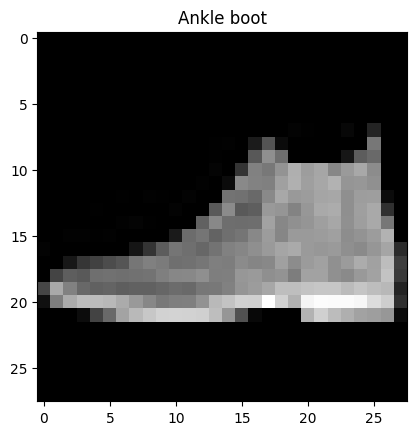

In [7]:
# Use iter to turn test_dataloader into an iterator, then use next to pull the first batch from it
batch = next(iter(test_dataloader))
print(type(batch))
print(len(batch))
X, y = batch
print(X.shape, X.dtype)
print(y.shape, y.dtype)
print("-"*100)

# Dataloader wraps a Dataset, so alternatively, pull this directly to inspect it
# You could have checked the object's attributes using dir(test_dataloader), one of which is another object called dataset
testset = test_dataloader.dataset
print(type(testset))
sample = testset[0]
print(type(sample), len(sample))
image, label = sample
print(image.shape, label)
print("-"*100)

# Check the size of the dataset itself
print(len(testset))
print(len(test_dataloader))
print("-"*100)

# Inspect the data stored in the dataset
import matplotlib.pyplot as plt
sample_img = testset[0][0]                 # pull the first pair and take the image from the 2-tuple
sample_img = sample_img.squeeze()          # use the torch squeeze attribute to remove unused dimensions: [1, 28, 28] -> [28, 28]

plt.imshow(sample_img, cmap="gray")
title = testset.classes[y[0]]             # extracted y from the lists earlier - select the correct class title using this index
plt.title(title)
plt.show()


Read more about [loading data in PyTorch](data_tutorial.html).


------------------------------------------------------------------------


Creating Models
===============

To define a neural network in PyTorch, we create a class that inherits
from
[nn.Module](https://pytorch.org/docs/stable/generated/torch.nn.Module.html).
We define the layers of the network in the `__init__` function and
specify how data will pass through the network in the `forward`
function. To accelerate operations in the neural network, we move it to
the
[accelerator](https://pytorch.org/docs/stable/torch.html#accelerators)
such as CUDA, MPS, MTIA, or XPU. If the current accelerator is
available, we will use it. Otherwise, we use the CPU.


In [8]:
device = torch.accelerator.current_accelerator().type if torch.accelerator.is_available() else "cpu"
print(f"Using {device} device")

# Define model
class NeuralNetwork(nn.Module):                     # Inherit from the nn.Module class so that we can inherit parameter tracking and hooks for free
    def __init__(self):
        super().__init__()                          # Keep the original __init__ function from nn.Module, but add our own layer structure to it
        self.flatten = nn.Flatten()                 # Add the .Flatten() funciton from the nn module directly to your model class (doesn't really make a difference in this case)
        self.linear_relu_stack = nn.Sequential(     # Use the .Sequential to build an object that passes inputs through all of your layers one by one
            nn.Linear(28*28, 512),                  # List the layers in order here (linear and activation functions)
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10)                      # Output of self.linear_relu_stack is a tensor of 10 values
        )

    def forward(self, x):                           # Define the forward function that takes input to model, and outputs the value from passing through it
        x = self.flatten(x)                         # Use the flatten function here to make sure input is the right shape
        logits = self.linear_relu_stack(x)
        return logits                               # Return tensor of 10 values

model = NeuralNetwork().to(device)                  # This line 1. calls __init__ which i) builds the flatten layer and sequential stack ii) randomly initialises all weights and biases. 2. moves all of the registered parameters to the chosen device (GPU in our case)
print(model)

Using cuda device
NeuralNetwork(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear_relu_stack): Sequential(
    (0): Linear(in_features=784, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=10, bias=True)
  )
)


Read more about [building neural networks in
PyTorch](buildmodel_tutorial.html).


In [13]:
import nvidia
!nvidia-smi     # ! prefix runs as a terminal command

Tue Oct 27 22:53:55 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   57C    P0             31W /   70W |     127MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

------------------------------------------------------------------------


Optimizing the Model Parameters
===============================

To train a model, we need a [loss
function](https://pytorch.org/docs/stable/nn.html#loss-functions) and an
[optimizer](https://pytorch.org/docs/stable/optim.html).


In [14]:
# Note that these have been defined outside of the model class
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=1e-3) # SGD takes as input 1. parameters attribute of our model 2. learning rate

In [18]:
params = list(model.parameters())
print(len(params))                 # number of parameter tensors
for p in params:
    print(p.shape)                 # output is each weight and bias tensor from the linear layers

6
torch.Size([512, 784])
torch.Size([512])
torch.Size([512, 512])
torch.Size([512])
torch.Size([10, 512])
torch.Size([10])


In a single training loop, the model makes predictions on the training
dataset (fed to it in batches), and backpropagates the prediction error
to adjust the model\'s parameters.


In [20]:
def train(dataloader, model, loss_fn, optimizer):                       # Takes 4 inputs in this case
    size = len(dataloader.dataset)
    model.train()                                                       # Put the model in training mode - allow dropout and batch statistics to be used
    for batch, (X, y) in enumerate(dataloader):                         # Dataloader is an iterable input to the function, we unpack the enumeration in this one line into batch index and image label pairs
        X, y = X.to(device), y.to(device)                               # Move to GPU

        # Compute prediction error
        pred = model(X)
        loss = loss_fn(pred, y)

        # Backpropagation
        loss.backward()                                                 # Do this for every training data point - use the inbuilt backward function
        optimizer.step()                                                # Update the weights and biases according to the SGD optimiser we defined
        optimizer.zero_grad()                                           # Gradients for each parameter accumulate if you don't manually clear them

        if batch % 100 == 0:                                            # "Every 100th batch index"
            loss, current = loss.item(), (batch + 1) * len(X)           # Current measures how many training samples have been processed this epoch
            print(f"loss: {loss:>7f}  [{current:>5d}/{size:>5d}]")

We also check the model\'s performance against the test dataset to
ensure it is learning.


In [21]:
def test(dataloader, model, loss_fn):                                                         # Note that the optimizer is not needed as input in the test function (no updates)
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()                                                                              # Switch to evaluation mode to prevent dropout / sample statistics being used
    test_loss, correct = 0, 0
    with torch.no_grad():                                                                     # Don't bother tracking gradients when testing the model
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)                                                                   # Pass the input into the model and see what it outputs
            test_loss += loss_fn(pred, y).item()
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()                   # .item() converts 1D torch tensors to Python floats
    test_loss /= num_batches
    correct /= size
    print(f"Test Error: \n Accuracy: {(100*correct):>0.1f}%, Avg loss: {test_loss:>8f} \n")

The training process is conducted over several iterations (*epochs*).
During each epoch, the model learns parameters to make better
predictions. We print the model\'s accuracy and loss at each epoch;
we\'d like to see the accuracy increase and the loss decrease with every
epoch.


In [22]:
epochs = 5
for t in range(epochs):
    print(f"Epoch {t+1}\n-------------------------------")
    train(train_dataloader, model, loss_fn, optimizer)
    test(test_dataloader, model, loss_fn)
print("Done!")

Epoch 1
-------------------------------
loss: 2.294752  [   64/60000]
loss: 2.287265  [ 6464/60000]
loss: 2.271406  [12864/60000]
loss: 2.276222  [19264/60000]
loss: 2.253087  [25664/60000]
loss: 2.226279  [32064/60000]
loss: 2.232616  [38464/60000]
loss: 2.196469  [44864/60000]
loss: 2.187363  [51264/60000]
loss: 2.175481  [57664/60000]
Test Error: 
 Accuracy: 52.4%, Avg loss: 2.157292 

Epoch 2
-------------------------------
loss: 2.150755  [   64/60000]
loss: 2.148417  [ 6464/60000]
loss: 2.093421  [12864/60000]
loss: 2.124926  [19264/60000]
loss: 2.075822  [25664/60000]
loss: 2.008501  [32064/60000]
loss: 2.042032  [38464/60000]
loss: 1.957232  [44864/60000]
loss: 1.960093  [51264/60000]
loss: 1.910026  [57664/60000]
Test Error: 
 Accuracy: 60.9%, Avg loss: 1.896595 

Epoch 3
-------------------------------
loss: 1.908619  [   64/60000]
loss: 1.890873  [ 6464/60000]
loss: 1.773090  [12864/60000]
loss: 1.833568  [19264/60000]
loss: 1.730225  [25664/60000]
loss: 1.657486  [32064/600

Read more about [Training your model](optimization_tutorial.html).


------------------------------------------------------------------------


Saving Models
=============

A common way to save a model is to serialize the internal state
dictionary (containing the model parameters).


In [23]:
torch.save(model.state_dict(), "model.pth")
print("Saved PyTorch Model State to model.pth")

Saved PyTorch Model State to model.pth


Loading Models
==============

The process for loading a model includes re-creating the model structure
and loading the state dictionary into it.


In [25]:
model = NeuralNetwork().to(device)                                  # Rebuild neural network structure from the defined class
model.load_state_dict(torch.load("model.pth", weights_only=True))   # Load the saved weights (weights_only is a safety to stop malicious code running)

<All keys matched successfully>

This model can now be used to make predictions.


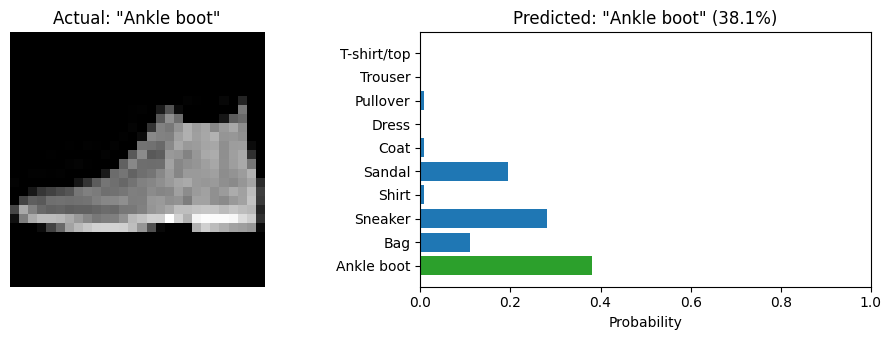

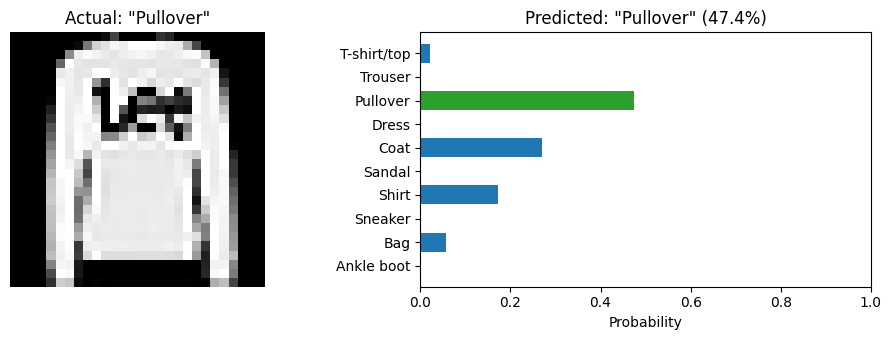

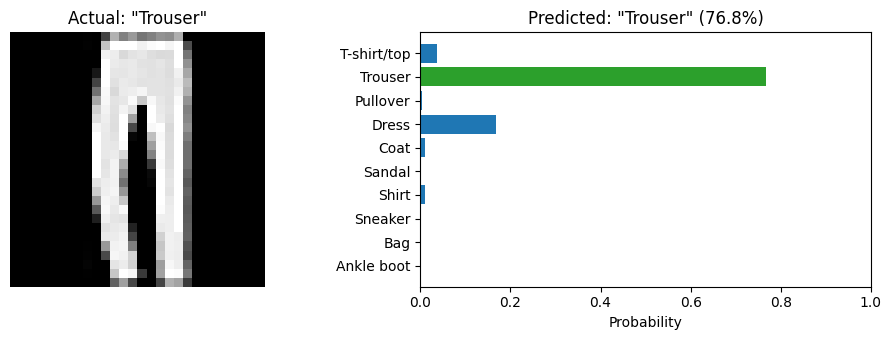

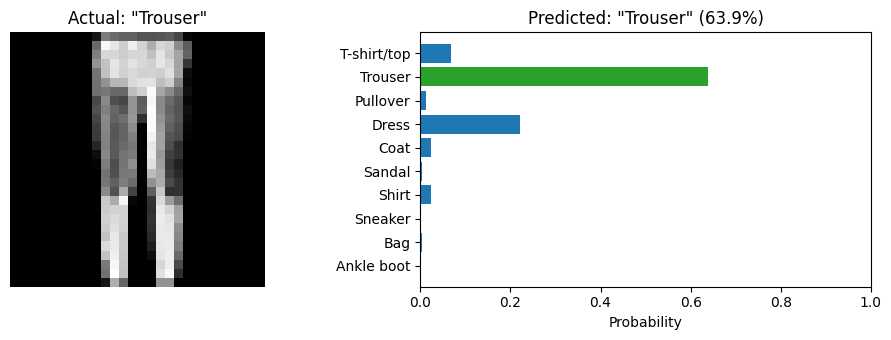

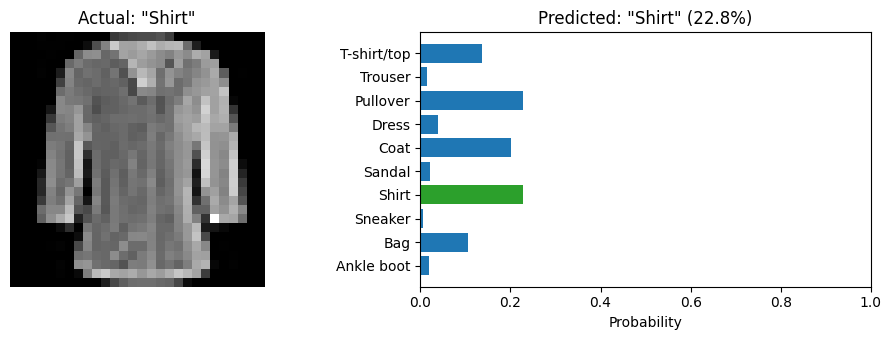

In [38]:
classes = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot",
]

model.eval()                                                      # Change the mode to evaluation mode again

test_length = 5
for i in range(test_length):
  x, y = test_data[i][0], test_data[i][1]
  with torch.no_grad():
      x = x.to(device)
      pred = model(x)

      # Get the image ready
      img = x.to("cpu")
      img = img.squeeze()

      # Prediction distribution from the model
      probabilities = pred.softmax(dim=1).squeeze().cpu()

  predicted = probabilities.argmax().item()

  # Image on the left, probability bars on the right
  fig, (ax_img, ax_bar) = plt.subplots(1, 2, figsize=(10, 3.5))

  ax_img.imshow(img, cmap="gray")
  ax_img.set_title(f'Actual: "{classes[y]}"')
  ax_img.axis("off")

  colours = ["tab:green" if j == predicted else "tab:blue" for j in range(len(classes))]
  ax_bar.barh(classes, probabilities.numpy(), color=colours)
  ax_bar.set_xlim(0, 1)
  ax_bar.invert_yaxis()                     # first class at the top
  ax_bar.set_xlabel("Probability")
  ax_bar.set_title(f'Predicted: "{classes[predicted]}" ({probabilities[predicted]:.1%})')

  plt.tight_layout()
  plt.show()

Read more about [Saving & Loading your
model](saveloadrun_tutorial.html).
